# S1.2 - Quality Report

## Objectif

Analyser la qualité technique du dataset à partir de :

01_data/metadata/inventory_v2.csv

## Questions étudiées

- Des problèmes ont-ils été détectés ?
- Quels formats sont présents ?
- Quels modes couleur sont présents ?
- Combien de canaux existent ?
- Les dimensions sont-elles homogènes ?
- Existe-t-il des anomalies visibles dans les métadonnées ?

## Livrable attendu

Quality Report

In [4]:
# Imports
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
print("ok")

ok


In [5]:
df_inventory = pd.read_csv(
    "../../01_data/metadata/inventory_v2.csv"
)
df_inventory.shape

(26402, 13)

In [6]:
df_inventory.head()

,source,culture,split,classe,filename,filepath,extension,format,width,height,mode,channels,problem
0,cacao_diseases,Cacao,unknown,black_pod_rot,black_pod_rot_1.jpg,..\..\01_data\raw\cacao_diseases\black_pod_rot...,.jpg,JPEG,1080,1080,RGB,3,none
1,cacao_diseases,Cacao,unknown,black_pod_rot,black_pod_rot_10.jpg,..\..\01_data\raw\cacao_diseases\black_pod_rot...,.jpg,JPEG,1080,1080,RGB,3,none
2,cacao_diseases,Cacao,unknown,black_pod_rot,black_pod_rot_100.jpg,..\..\01_data\raw\cacao_diseases\black_pod_rot...,.jpg,JPEG,1080,1080,RGB,3,none
3,cacao_diseases,Cacao,unknown,black_pod_rot,black_pod_rot_101.jpg,..\..\01_data\raw\cacao_diseases\black_pod_rot...,.jpg,JPEG,1080,1080,RGB,3,none
4,cacao_diseases,Cacao,unknown,black_pod_rot,black_pod_rot_102.jpg,..\..\01_data\raw\cacao_diseases\black_pod_rot...,.jpg,JPEG,1080,1080,RGB,3,none


In [7]:
df_inventory.info()

<class 'pandas.DataFrame'>
RangeIndex: 26402 entries, 0 to 26401
Data columns (total 13 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   source     26402 non-null  str  
 1   culture    26402 non-null  str  
 2   split      26402 non-null  str  
 3   classe     26402 non-null  str  
 4   filename   26402 non-null  str  
 5   filepath   26402 non-null  str  
 6   extension  26402 non-null  str  
 7   format     26402 non-null  str  
 8   width      26402 non-null  int64
 9   height     26402 non-null  int64
 10  mode       26402 non-null  str  
 11  channels   26402 non-null  int64
 12  problem    26402 non-null  str  
dtypes: int64(3), str(10)
memory usage: 2.6 MB


In [8]:
df_inventory["problem"].value_counts()

problem
none    26402
Name: count, dtype: int64

In [9]:
df_inventory[["width", "height"]].describe()

,width,height
count,26402.000000,26402.000000
mean,429.376259,429.376259
std,426.672449,426.672449
min,256.000000,256.000000
25%,256.000000,256.000000
50%,256.000000,256.000000
75%,256.000000,256.000000
max,2160.000000,2160.000000


In [10]:
df_inventory[["width", "height"]].value_counts()

width  height
256    256       22012
1080   1080       3501
2160   2160        889
Name: count, dtype: int64

In [11]:
df_inventory["channels"].value_counts()

channels
3    26402
Name: count, dtype: int64

In [12]:
df_inventory["mode"].value_counts()

mode
RGB    26402
Name: count, dtype: int64

In [13]:
df_inventory["format"].value_counts()

format
JPEG    26402
Name: count, dtype: int64

In [14]:
df_inventory[["source", "width", "height"]].value_counts()

source          width  height
PlantVillage    256    256       22012
cacao_diseases  1080   1080       3501
                2160   2160        889
Name: count, dtype: int64

In [15]:
dimensions = df_inventory[["width","height"]].value_counts()
type(dimensions)

pandas.Series

In [16]:
#tranformation en dataframe
dimensions = (dimensions.to_frame().reset_index())

In [17]:
dimensions

,width,height,count
0,256,256,22012
1,1080,1080,3501
2,2160,2160,889


In [18]:
dimensions["dimension"] = (dimensions["width"].astype(str)+" X "+dimensions["height"].astype(str))
dimensions

,width,height,count,dimension
0,256,256,22012,256 X 256
1,1080,1080,3501,1080 X 1080
2,2160,2160,889,2160 X 2160


In [19]:
type(dimensions)

pandas.DataFrame

## Traitement de l'audit géometrique(taille & déformation)

In [20]:
#Ajout de colone ratio à df_inventory
df_inventory["ratio"]=df_inventory["width"]/df_inventory["height"]
df_inventory["ratio"].head()

0    1.0
1    1.0
2    1.0
3    1.0
4    1.0
Name: ratio, dtype: float64

In [21]:
df_inventory["ratio"].describe()

count    26402.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
Name: ratio, dtype: float64

In [22]:
#ratios exxtremes
ratio_extreme=((df_inventory["ratio"] < 0.5)|(df_inventory["ratio"]>2.0))
ratio_extreme.sum()

np.int64(0)

In [23]:
#resolution insuffisante
reso_insufisante=((df_inventory["width"]<64) | (df_inventory["height"]<64))
reso_insufisante.sum()

np.int64(0)

## Audit d'expositon(Luminosité)

In [24]:
from PIL import Image
import numpy as np

In [25]:
exposure_status_values = []
brightness_values = []
for path in df_inventory["filepath"]:
    img=Image.open(path)
    img_gray = img.convert("L")
    pixels = np.array(img_gray)
    mean_brightness = pixels.mean()
    if(mean_brightness<15):
        exposure_status="underexposed"
    elif(mean_brightness>240):
        exposure_status="overexposed"
    else:
        exposure_status="normale"
    brightness_values.append(mean_brightness)
    exposure_status_values.append(exposure_status)

In [26]:
brightness_values[:5]

[np.float64(102.6697848079561),
 np.float64(121.77824674211249),
 np.float64(120.44626371742112),
 np.float64(139.77600737311386),
 np.float64(125.1527572016461)]

In [27]:
exposure_status_values[ :5] 

['normale', 'normale', 'normale', 'normale', 'normale']

In [28]:
len(brightness_values)

26402

In [29]:
df_inventory["brightness_mean"] = brightness_values

df_inventory["exposure_status"] = exposure_status_values

In [30]:
df_inventory["exposure_status"].value_counts()

exposure_status
normale         26387
underexposed       15
Name: count, dtype: int64

## inspection des 15 images sous-exposées

In [31]:
df_underexposed = df_inventory[
    df_inventory["exposure_status"] == "underexposed"
]

df_underexposed[
    [
        "source",
        "culture",
        "classe",
        "filepath",
        "brightness_mean"
    ]
]

,source,culture,classe,filepath,brightness_mean
11365,PlantVillage,Tomato,Tomato___Late_blight,..\..\01_data\raw\PlantVillage\train\Tomato___...,10.714142
11370,PlantVillage,Tomato,Tomato___Late_blight,..\..\01_data\raw\PlantVillage\train\Tomato___...,14.292572
11413,PlantVillage,Tomato,Tomato___Late_blight,..\..\01_data\raw\PlantVillage\train\Tomato___...,9.073990
11692,PlantVillage,Tomato,Tomato___Late_blight,..\..\01_data\raw\PlantVillage\train\Tomato___...,13.807983
11960,PlantVillage,Tomato,Tomato___Late_blight,..\..\01_data\raw\PlantVillage\train\Tomato___...,10.304947
12035,PlantVillage,Tomato,Tomato___Late_blight,..\..\01_data\raw\PlantVillage\train\Tomato___...,12.936447
12094,PlantVillage,Tomato,Tomato___Late_blight,..\..\01_data\raw\PlantVillage\train\Tomato___...,11.987823
12156,PlantVillage,Tomato,Tomato___Late_blight,..\..\01_data\raw\PlantVillage\train\Tomato___...,12.559372
12229,PlantVillage,Tomato,Tomato___Late_blight,..\..\01_data\raw\PlantVillage\train\Tomato___...,12.747787
12330,PlantVillage,Tomato,Tomato___Late_blight,..\..\01_data\raw\PlantVillage\train\Tomato___...,13.147537


In [32]:
df_underexposed.sort_values(
    by="brightness_mean"
)[
    [
        "source",
        "culture",
        "classe",
        "brightness_mean",
        "filepath"
    ]
].head()

,source,culture,classe,brightness_mean,filepath
24068,PlantVillage,Tomato,Tomato___Late_blight,8.246216,..\..\01_data\raw\PlantVillage\val\Tomato___La...
11413,PlantVillage,Tomato,Tomato___Late_blight,9.073990,..\..\01_data\raw\PlantVillage\train\Tomato___...
23766,PlantVillage,Tomato,Tomato___Late_blight,9.820343,..\..\01_data\raw\PlantVillage\val\Tomato___La...
11960,PlantVillage,Tomato,Tomato___Late_blight,10.304947,..\..\01_data\raw\PlantVillage\train\Tomato___...
11365,PlantVillage,Tomato,Tomato___Late_blight,10.714142,..\..\01_data\raw\PlantVillage\train\Tomato___...


In [33]:
df_underexposed.sort_values(
    by="brightness_mean"
).head()

,source,culture,split,classe,filename,filepath,extension,format,width,height,mode,channels,problem,ratio,brightness_mean,exposure_status
24068,PlantVillage,Tomato,val,Tomato___Late_blight,ed974f5b-e999-46a9-9e22-da51da2766b6___GHLB_PS...,..\..\01_data\raw\PlantVillage\val\Tomato___La...,.jpg,JPEG,256,256,RGB,3,none,1.0,8.246216,underexposed
11413,PlantVillage,Tomato,train,Tomato___Late_blight,17fcb016-4663-4f95-bc0b-b40392235015___GHLB_PS...,..\..\01_data\raw\PlantVillage\train\Tomato___...,.jpg,JPEG,256,256,RGB,3,none,1.0,9.073990,underexposed
23766,PlantVillage,Tomato,val,Tomato___Late_blight,1f2dc4ae-5264-443a-a103-67fafb37bc70___GHLB_PS...,..\..\01_data\raw\PlantVillage\val\Tomato___La...,.jpg,JPEG,256,256,RGB,3,none,1.0,9.820343,underexposed
11960,PlantVillage,Tomato,train,Tomato___Late_blight,7b343a4c-5fbc-40f6-83da-ccae49ebd5fb___GHLB_PS...,..\..\01_data\raw\PlantVillage\train\Tomato___...,.jpg,JPEG,256,256,RGB,3,none,1.0,10.304947,underexposed
11365,PlantVillage,Tomato,train,Tomato___Late_blight,1159051e-1278-4b35-929c-e26b963d048f___GHLB_PS...,..\..\01_data\raw\PlantVillage\train\Tomato___...,.jpg,JPEG,256,256,RGB,3,none,1.0,10.714142,underexposed


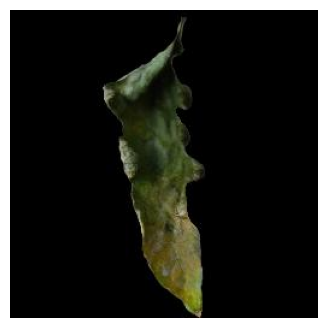

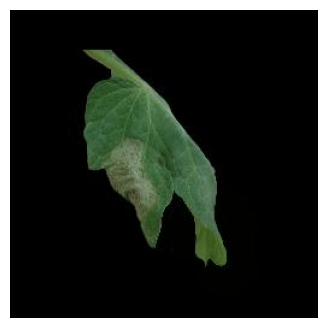

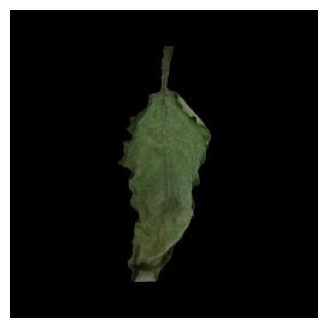

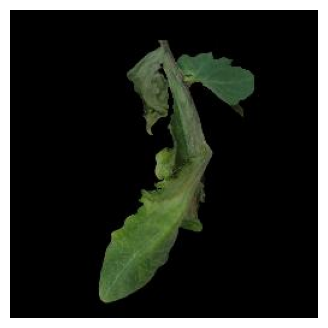

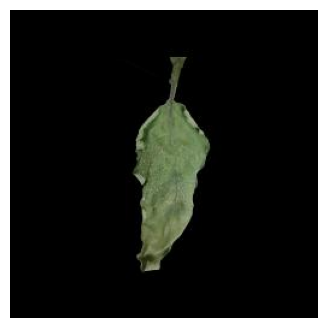

In [34]:
from PIL import Image
import matplotlib.pyplot as plt

for path in df_underexposed["filepath"].head(5):

    img = Image.open(path)
    plt.figure(figsize=(4,4))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

## Le Boxplot des Outliers Géométriques 

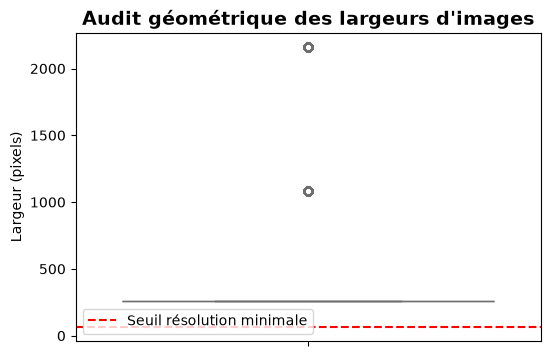

In [35]:
plt.figure(figsize=(6, 4))

sns.boxplot(
    data=df_inventory,
    y="width",
    color="skyblue"
)

plt.axhline(
    y=64,
    color="red",
    linestyle="--",
    label="Seuil résolution minimale"
)

plt.title(
    "Audit géométrique des largeurs d'images",
    fontsize=14,
    fontweight="bold"
)

plt.ylabel("Largeur (pixels)")

plt.legend()

plt.show()

### Interprétation

Le boxplot des largeurs montre qu'aucune image
n'est située sous le seuil minimal de 64 pixels.

La ligne rouge matérialisant le seuil de qualité
reste largement en dessous de l'ensemble des
observations.

Le graphique confirme les résultats de l'audit
géométrique automatique.

Aucun cas de résolution insuffisante n'a été détecté.

**Décision :**

Aucune image n'est rejetée pour cause
de taille insuffisante.

### L'Histogramme du Ratio d'Aspect(taile et deformation)

Text(0, 0.5, 'frequence par ratio')

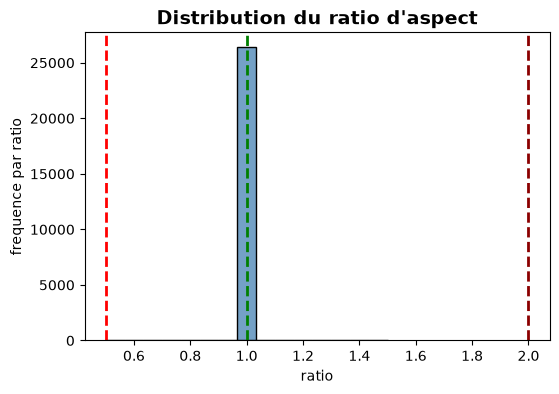

In [36]:
plt.figure(figsize=(6,4))
sns.histplot(
    data=df_inventory,
    x="ratio",
    bins=15,
    color="steelblue",
)
plt.axvline(
    x=1.0,
    color="green",
    linestyle="--",
    linewidth=2,
    label="image à forma carré parfait(ratio=1)"
)

plt.axvline(
    x=0.5,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Seuil ratio minimal"
)


plt.axvline(
    x=2.0,
    color="darkred",
    linestyle="--",
    linewidth=2,
    label="Seuil ratio maximal"
)

plt.title("Distribution du ratio d'aspect", fontsize=14, fontweight="bold")

plt.ylabel("frequence par ratio")

### Interprétation

L'histogramme montre une concentration totale des
observations autour d'un ratio de 1.

Les lignes rouges matérialisant les seuils
de contrôle (0.5 et 2.0) ne contiennent
aucune observation.

Le graphique confirme que toutes les images
du dataset possèdent un ratio d'aspect normal.

Aucune image n'est affectée par une
déformation géométrique excessive

## le barblot(diagramme en bar) d'exposition(luminosité)

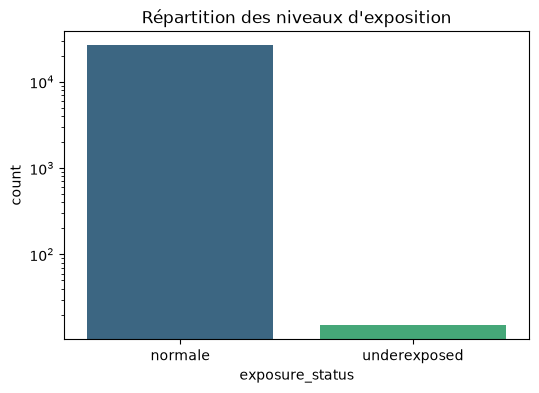

In [37]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df_inventory,
    x="exposure_status",
    hue="exposure_status",
    palette="viridis",
    legend=False
)

plt.yscale("log")

plt.title("Répartition des niveaux d'exposition")
plt.show()

### Interprétation

Le graphique montre qu'une très grande majorité
des images possède une exposition normale.

Seules 15 images ont été détectées comme
sous-exposées.

Aucune image sur-exposée n'a été détectée.

L'audit d'exposition confirme que le dataset
présente une qualité visuelle globalement satisfaisante.

Les images sous-exposées ont été inspectées
manuellement et conservées car les feuilles
et les symptômes demeurent visibles.

**Décision :**

Aucune image n'est rejetée pour cause
d'exposition incorrecte.

## Barplot horizontal de synthèse de qulité

In [38]:
quality_summary = pd.DataFrame({
    "categorie": [
        "Fichiers vides",
        "Formats invalides",
        "Résolution insuffisante",
        "Ratio extrême",
        "Sous-exposées",
        "Sur-exposées"
    ],
    "count": [
        0,
        0,
        0,
        0,
        15,
        0
    ]
})

C:\Users\HP\AppData\Local\Temp\ipykernel_19168\4108321297.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


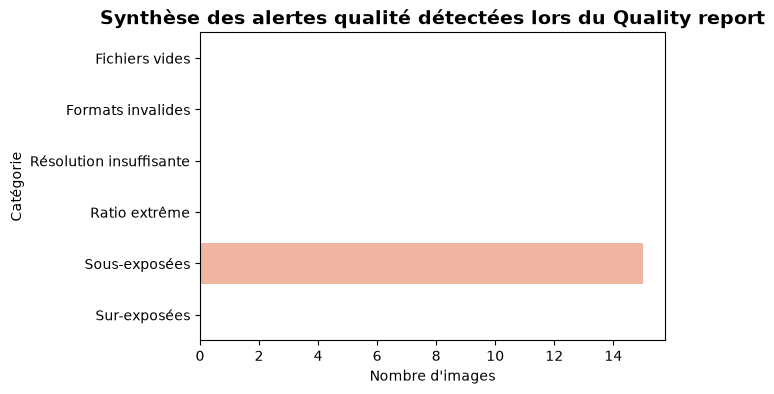

In [39]:
plt.figure(figsize=(6,4))

sns.barplot(
    data=quality_summary,
    x="count",
    y="categorie",
    palette="Reds_r"
)

plt.title(
    "Synthèse des alertes qualité détectées lors du Quality report",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Nombre d'images")
plt.ylabel("Catégorie")

plt.show()

### Interprétation

Le graphique de synthèse montre que l'ensemble des contrôles qualité
effectués sur le dataset n'a révélé aucune anomalie critique.

Aucun fichier vide, aucun format invalide, aucune résolution
insuffisante et aucun ratio extrême n'ont été détectés.

Seules 15 images ont été signalées comme sous-exposées.

Une inspection visuelle a confirmé que ces images restent
exploitables et qu'elles ne justifient pas une exclusion.

Décision :

Aucune image n'est rejetée lors de cette phase
d'audit qualité.

Le Data Health Index est de 100 %.

# Conclusion du Quality Report

L'audit qualité réalisé sur les 26 402 images du projet AgriLens montre que le dataset présente un excellent niveau de qualité technique.

L'analyse de l'intégrité physique n'a révélé aucun fichier vide ou inaccessible. La validation des formats a confirmé que toutes les images sont des fichiers JPEG valides et exploitables. L'audit chromatique a montré une homogénéité complète du dataset avec des images exclusivement au format RGB et composées de trois canaux couleurs, garantissant leur compatibilité avec les futurs modèles de Deep Learning.

L'audit géométrique a confirmé l'absence d'images à résolution insuffisante et l'absence de ratios d'aspect extrêmes. Toutes les images possèdent un ratio de 1, ce qui signifie que l'ensemble du dataset est constitué d'images carrées. Les dimensions observées restent cohérentes avec les exigences du projet et aucune anomalie géométrique n'a été détectée.

L'audit d'exposition a identifié 15 images présentant une luminosité moyenne inférieure au seuil défini pour la sous-exposition. Une inspection visuelle a cependant montré que les feuilles et les symptômes restaient clairement visibles. Ces images ont donc été classées comme alertes qualité et non comme rejets qualité. Elles seront conservées dans le dataset et pourront faire l'objet d'améliorations spécifiques lors des futures étapes de prétraitement.

Aucune image n'a finalement été exclue du dataset au cours de cette phase d'audit. Le Data Health Index obtenu est de 100 %, témoignant d'un niveau de qualité global très élevé.

Le dataset est considéré comme techniquement sain et suffisamment fiable pour poursuivre les prochaines étapes du projet, notamment la détection des doublons, la prévention du leakage, la création des jeux Train/Validation/Test, la construction des couches Bronze/Silver/Gold et les futures analyses exploratoires (EDA).

In [40]:
df_inventory.info()


<class 'pandas.DataFrame'>
RangeIndex: 26402 entries, 0 to 26401
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   source           26402 non-null  str    
 1   culture          26402 non-null  str    
 2   split            26402 non-null  str    
 3   classe           26402 non-null  str    
 4   filename         26402 non-null  str    
 5   filepath         26402 non-null  str    
 6   extension        26402 non-null  str    
 7   format           26402 non-null  str    
 8   width            26402 non-null  int64  
 9   height           26402 non-null  int64  
 10  mode             26402 non-null  str    
 11  channels         26402 non-null  int64  
 12  problem          26402 non-null  str    
 13  ratio            26402 non-null  float64
 14  brightness_mean  26402 non-null  float64
 15  exposure_status  26402 non-null  str    
dtypes: float64(2), int64(3), str(11)
memory usage: 3.2 MB


In [41]:
# Calcul des empreintes MD5

import hashlib

md5_hash_values = []

for path in df_inventory["filepath"]:
    with open(path, "rb") as f:
        data = f.read()

    md5_hash = hashlib.md5(data).hexdigest()

    md5_hash_values.append(md5_hash)

In [42]:
# Vérification

len(md5_hash_values)

md5_hash_values[:5]

['3cf3901bd20e3910ce2bd2a34285e151',
 '2473be012438c8db2a0c1f454c226928',
 'af88d5ff63102933d009e06602aa9aa8',
 'd33754ff3dc4621047583561bc442850',
 'd7b2a39d2eac0a869f5510581943bed2']

In [43]:
# Ajout de la colonne MD5

df_inventory["md5_hash"] = md5_hash_values

In [44]:
# Vérification

df_inventory["md5_hash"].head()

0    3cf3901bd20e3910ce2bd2a34285e151
1    2473be012438c8db2a0c1f454c226928
2    af88d5ff63102933d009e06602aa9aa8
3    d33754ff3dc4621047583561bc442850
4    d7b2a39d2eac0a869f5510581943bed2
Name: md5_hash, dtype: str

In [45]:
# Recherche des doublons exacts

duplicates = df_inventory[
    df_inventory["md5_hash"].duplicated(
        keep=False
    )
]

In [46]:
# Nombre de groupes de doublons

duplicates["md5_hash"].nunique()

14

In [47]:
# Images appartenant à un doublon

duplicates[
    [
        "source",
        "split",
        "classe",
        "filename",
        "md5_hash"
    ]
].sort_values("md5_hash")

,source,split,classe,filename,md5_hash
12630,PlantVillage,train,Tomato___Late_blight,e5d707cd-077c-43af-bda9-6138e516ff51___GHLB2 L...,0e0dcd876f5b32cac9da836b2e783d91
11817,PlantVillage,train,Tomato___Late_blight,5f21282c-e2ef-4c4a-ace1-b5701fe7effc___GHLB2 L...,0e0dcd876f5b32cac9da836b2e783d91
11423,PlantVillage,train,Tomato___Late_blight,1a69b38b-c4eb-42c4-9584-bcb14fb8db0c___GHLB2 L...,1d87a50fa691cef6f476b20bb48cfaf8
11529,PlantVillage,train,Tomato___Late_blight,2c47b891-3c97-48f1-a2cc-5aa53d3a1148___GHLB2 L...,1d87a50fa691cef6f476b20bb48cfaf8
10247,PlantVillage,train,Tomato___healthy,37203047-d8ba-43f7-b31e-d496c41c569c___GH_HL L...,2e53ad1ec3f810e2ff4c83400dc69ec9
10395,PlantVillage,train,Tomato___healthy,505465db-407b-4e0a-8110-7479dad5261c___GH_HL L...,2e53ad1ec3f810e2ff4c83400dc69ec9
10242,PlantVillage,train,Tomato___healthy,34c81c57-e1fa-49dd-a49d-34fe8b2385fe___GH_HL L...,32cb22521edc69a5503a6749446dd522
23404,PlantVillage,val,Tomato___healthy,068e324c-faf6-40d6-8f83-578907f1cac5___GH_HL L...,32cb22521edc69a5503a6749446dd522
11692,PlantVillage,train,Tomato___Late_blight,48c55974-9fe9-4f4b-94f7-c8cd127d1e05___GHLB_PS...,3b227920ba50ce0a4602b258f624e935
12367,PlantVillage,train,Tomato___Late_blight,bd4f09bd-ee85-4ab1-bce0-8cde3fdd7f1b___GHLB_PS...,3b227920ba50ce0a4602b258f624e935


In [48]:
# Nombre de splits par hash

leakage_groups = (
    duplicates.groupby("md5_hash")["split"]
    .nunique()
)

leakage_groups

md5_hash
0e0dcd876f5b32cac9da836b2e783d91    1
1d87a50fa691cef6f476b20bb48cfaf8    1
2e53ad1ec3f810e2ff4c83400dc69ec9    1
32cb22521edc69a5503a6749446dd522    2
3b227920ba50ce0a4602b258f624e935    1
3dab5eb1192b5c43fd3015490cf0b18f    1
4b73700b68ce8704f6b4549a2846dede    1
4bab4aa40d89e19ed72d8b8d501b1db8    2
5bdbdc7333be3ab35ef81ec17ce14816    2
6e48e89e89da343b6b90ccda5b18d698    2
bf12be065849d781b7da2e79091b1072    1
c1b24c8caaa06e756560a83d7358579e    1
ca06650efa30a3f6731df694f07b4690    2
ea0a44df2e4e44c6ccacc31f067a6284    1
Name: split, dtype: int64

In [49]:
# Groupes présents dans plusieurs splits

leakage_groups[
    leakage_groups > 1
]

md5_hash
32cb22521edc69a5503a6749446dd522    2
4bab4aa40d89e19ed72d8b8d501b1db8    2
5bdbdc7333be3ab35ef81ec17ce14816    2
6e48e89e89da343b6b90ccda5b18d698    2
ca06650efa30a3f6731df694f07b4690    2
Name: split, dtype: int64

In [50]:
# Nombre de groupes à risque

len(
    leakage_groups[
        leakage_groups > 1
    ]
)

5

In [51]:
# Hash concernés par le leakage

leakage_md5 = (
    leakage_groups[
        leakage_groups > 1
    ].index
)

leakage_md5

Index(['32cb22521edc69a5503a6749446dd522', '4bab4aa40d89e19ed72d8b8d501b1db8',
       '5bdbdc7333be3ab35ef81ec17ce14816', '6e48e89e89da343b6b90ccda5b18d698',
       'ca06650efa30a3f6731df694f07b4690'],
      dtype='str', name='md5_hash')

In [52]:
# Marquage des doublons exacts

duplicate_md5 = duplicates["md5_hash"].unique()

df_inventory["duplicate_exact"] = (
    df_inventory["md5_hash"]
    .isin(duplicate_md5)
)

In [53]:
# Vérification

df_inventory["duplicate_exact"].value_counts()

duplicate_exact
False    26374
True        28
Name: count, dtype: int64

## 5 groupes présententent un leakage Train - Validation  et 9 groupe dans le meme split(donc pas de leakage pour les 9, juste doublon interne)


In [54]:
## Marquage des risques de leakage

df_inventory["leakage_risk"] = (
    df_inventory["md5_hash"]
    .isin(leakage_md5)
)

In [55]:
# Vérification

df_inventory["leakage_risk"].value_counts()

leakage_risk
False    26392
True        10
Name: count, dtype: int64

In [56]:
# Images à risque de leakage

df_inventory[
    df_inventory["leakage_risk"]
][
    [
        "source",
        "classe",
        "split",
        "filename",
        "md5_hash"
    ]
].sort_values("md5_hash")

,source,classe,split,filename,md5_hash
10242,PlantVillage,Tomato___healthy,train,34c81c57-e1fa-49dd-a49d-34fe8b2385fe___GH_HL L...,32cb22521edc69a5503a6749446dd522
23404,PlantVillage,Tomato___healthy,val,068e324c-faf6-40d6-8f83-578907f1cac5___GH_HL L...,32cb22521edc69a5503a6749446dd522
12156,PlantVillage,Tomato___Late_blight,train,98586693-fe1f-4ea0-8e27-4501b61cf09b___GHLB_PS...,4bab4aa40d89e19ed72d8b8d501b1db8
23997,PlantVillage,Tomato___Late_blight,val,c1775bad-7c02-41fb-bb7d-f8df91d60ac3___GHLB_PS...,4bab4aa40d89e19ed72d8b8d501b1db8
12526,PlantVillage,Tomato___Late_blight,train,d6e6897a-5083-4914-9903-804c5684a956___GHLB2 L...,5bdbdc7333be3ab35ef81ec17ce14816
24044,PlantVillage,Tomato___Late_blight,val,d81682aa-746b-4e07-af2b-52ebb6f4c017___GHLB2 L...,5bdbdc7333be3ab35ef81ec17ce14816
10811,PlantVillage,Tomato___healthy,train,a5de43e7-fc2f-4a14-a8e6-c0f2f94c84f1___GH_HL L...,6e48e89e89da343b6b90ccda5b18d698
23480,PlantVillage,Tomato___healthy,val,488feb1c-4b9f-44e7-8aa6-4103a9601f5f___GH_HL L...,6e48e89e89da343b6b90ccda5b18d698
12600,PlantVillage,Tomato___Late_blight,train,e20107e7-137f-400e-817f-5dc4c58e5d70___GHLB2 L...,ca06650efa30a3f6731df694f07b4690
23844,PlantVillage,Tomato___Late_blight,val,5688ea99-c949-41d0-bbab-9cbf0ffb8bcd___GHLB2 L...,ca06650efa30a3f6731df694f07b4690


In [57]:
# Résumé

print(
    f"Images dans un groupe de doublons : "
    f"{df_inventory['duplicate_exact'].sum()}"
)

print(
    f"Images à risque de leakage : "
    f"{df_inventory['leakage_risk'].sum()}"
)

Images dans un groupe de doublons : 28
Images à risque de leakage : 10


In [58]:
# Copies Validation à supprimer

to_remove = df_inventory[
    (df_inventory["leakage_risk"] == True)
    &
    (df_inventory["split"] == "val")
]

In [59]:
# Vérification

to_remove.shape

to_remove[
    [
        "classe",
        "split",
        "filename",
        "md5_hash"
    ]
]

,classe,split,filename,md5_hash
23404,Tomato___healthy,val,068e324c-faf6-40d6-8f83-578907f1cac5___GH_HL L...,32cb22521edc69a5503a6749446dd522
23480,Tomato___healthy,val,488feb1c-4b9f-44e7-8aa6-4103a9601f5f___GH_HL L...,6e48e89e89da343b6b90ccda5b18d698
23844,Tomato___Late_blight,val,5688ea99-c949-41d0-bbab-9cbf0ffb8bcd___GHLB2 L...,ca06650efa30a3f6731df694f07b4690
23997,Tomato___Late_blight,val,c1775bad-7c02-41fb-bb7d-f8df91d60ac3___GHLB_PS...,4bab4aa40d89e19ed72d8b8d501b1db8
24044,Tomato___Late_blight,val,d81682aa-746b-4e07-af2b-52ebb6f4c017___GHLB2 L...,5bdbdc7333be3ab35ef81ec17ce14816


In [60]:
# Création du dataset nettoyé

df_inventory_clean = df_inventory[
    ~(
        (df_inventory["leakage_risk"] == True)
        &
        (df_inventory["split"] == "val")
    )
].copy()

In [61]:
df_inventory.shape

(26402, 19)

In [62]:


df_inventory_clean.shape

(26397, 19)

In [63]:
# Doublons restants

duplicates_clean = df_inventory_clean[
    df_inventory_clean["md5_hash"].duplicated(
        keep=False
    )
]

In [64]:
# Contrôle final du leakage

duplicates_clean.groupby(
    "md5_hash"
)["split"].nunique()

md5_hash
0e0dcd876f5b32cac9da836b2e783d91    1
1d87a50fa691cef6f476b20bb48cfaf8    1
2e53ad1ec3f810e2ff4c83400dc69ec9    1
3b227920ba50ce0a4602b258f624e935    1
3dab5eb1192b5c43fd3015490cf0b18f    1
4b73700b68ce8704f6b4549a2846dede    1
bf12be065849d781b7da2e79091b1072    1
c1b24c8caaa06e756560a83d7358579e    1
ea0a44df2e4e44c6ccacc31f067a6284    1
Name: split, dtype: int64

In [65]:
# Aperçu final

df_inventory_clean.info()

<class 'pandas.DataFrame'>
Index: 26397 entries, 0 to 26401
Data columns (total 19 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   source           26397 non-null  str    
 1   culture          26397 non-null  str    
 2   split            26397 non-null  str    
 3   classe           26397 non-null  str    
 4   filename         26397 non-null  str    
 5   filepath         26397 non-null  str    
 6   extension        26397 non-null  str    
 7   format           26397 non-null  str    
 8   width            26397 non-null  int64  
 9   height           26397 non-null  int64  
 10  mode             26397 non-null  str    
 11  channels         26397 non-null  int64  
 12  problem          26397 non-null  str    
 13  ratio            26397 non-null  float64
 14  brightness_mean  26397 non-null  float64
 15  exposure_status  26397 non-null  str    
 16  md5_hash         26397 non-null  str    
 17  duplicate_exact  26397 non-n

In [66]:
df_inventory_clean.info()

<class 'pandas.DataFrame'>
Index: 26397 entries, 0 to 26401
Data columns (total 19 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   source           26397 non-null  str    
 1   culture          26397 non-null  str    
 2   split            26397 non-null  str    
 3   classe           26397 non-null  str    
 4   filename         26397 non-null  str    
 5   filepath         26397 non-null  str    
 6   extension        26397 non-null  str    
 7   format           26397 non-null  str    
 8   width            26397 non-null  int64  
 9   height           26397 non-null  int64  
 10  mode             26397 non-null  str    
 11  channels         26397 non-null  int64  
 12  problem          26397 non-null  str    
 13  ratio            26397 non-null  float64
 14  brightness_mean  26397 non-null  float64
 15  exposure_status  26397 non-null  str    
 16  md5_hash         26397 non-null  str    
 17  duplicate_exact  26397 non-n

In [ ]:
# L'Audit Spatial et Géométrique Composite 

NameError: name 'df' is not defined

## Audit des doublons exacts et correction du leakage

Un hachage MD5 a été calculé pour chacune des 26 402 images du dataset afin de détecter les doublons exacts.

### Résultats

14 groupes de doublons exacts ont été détectés.

Ces groupes représentent

### Limites de la méthode

La détection réalisée dans cette étape repose sur le hachage MD5.

Cette approche est très efficace pour identifier les doublons exacts car deux fichiers possédant le même contenu binaire produisent la même empreinte numérique.

Cependant, cette méthode présente une limite importante : elle ne détecte pas les images visuellement similaires mais numériquement différentes.

Par exemple, les cas suivants ne seraient pas détectés comme des doublons par MD5 :

- image recadrée ;
- image redimensionnée ;
- image légèrement plus lumineuse ;
- image avec un contraste modifié ;
- image réenregistrée avec une compression différente.

Dans ces situations, les images peuvent rester visuellement très proches tout en produisant des empreintes MD5 totalement différentes.

L'absence de doublons exacts ne garantit donc pas l'absence de quasi-doublons.

### Prochaine étape

La prochaine phase consistera à rechercher les quasi-doublons afin d'identifier les images visuellement similaires pouvant encore introduire du data leakage ou biaiser l'évaluation des futurs modèles.

Cette analyse viendra compléter l'audit des doublons exacts réalisé par MD5 et permettra d'obtenir un niveau de confiance plus élevé dans la qualité et l'indépendance des données.
``

In [67]:
import imagehash
from PIL import Image

In [68]:
# Calcul des empreintes perceptuelles
phash_values = []

for path in df_inventory_clean["filepath"]:
    
    img = Image.open(path)

    phash = imagehash.phash(img)

    phash_values.append(str(phash))

In [69]:
# Vérification

len(phash_values)

phash_values[:5]

['da95a424acb2f2d3',
 'eef242f7a310b18a',
 'd1f58ff12f01ba04',
 'a116ee225d6a496f',
 'eeec88a22f1db215']

In [70]:
phash_values[:5]

['da95a424acb2f2d3',
 'eef242f7a310b18a',
 'd1f58ff12f01ba04',
 'a116ee225d6a496f',
 'eeec88a22f1db215']

In [71]:
# Ajout de la colonne pHash

df_inventory_clean["phash"] = phash_values

In [72]:
# Vérification

df_inventory_clean["phash"].head()

0    da95a424acb2f2d3
1    eef242f7a310b18a
2    d1f58ff12f01ba04
3    a116ee225d6a496f
4    eeec88a22f1db215
Name: phash, dtype: str

In [73]:
# Recherche des pHash identiques

df_inventory_clean["phash"].duplicated().sum()

np.int64(10)

In [74]:
# Extraction des groupes détectés

duplicates_phash = df_inventory_clean[
    df_inventory_clean["phash"].duplicated(
        keep=False
    )
]

In [75]:
# Inspection des groupes

duplicates_phash[
    [
        "classe",
        "split",
        "filename",
        "phash"
    ]
].sort_values("phash")

,classe,split,filename,phash
6309,Corn_(maize)___healthy,train,94ca39a0-d4df-44c6-b5cc-a38a754506e5___R.S_HL ...,8080a02b9abb6fff
22474,Corn_(maize)___healthy,val,8afc9635-c5e3-41be-aac0-74109d6112ed___R.S_HL ...,8080a02b9abb6fff
11023,Tomato___healthy,train,cfd491d6-4af5-4728-8f0e-0d330a07174a___GH_HL L...,8cf171cd06c6732e
10107,Tomato___healthy,train,1af0bfe1-4bcf-4b8b-be66-5d0953eb647e___GH_HL L...,8cf171cd06c6732e
12367,Tomato___Late_blight,train,bd4f09bd-ee85-4ab1-bce0-8cde3fdd7f1b___GHLB_PS...,9931664c736639e6
11692,Tomato___Late_blight,train,48c55974-9fe9-4f4b-94f7-c8cd127d1e05___GHLB_PS...,9931664c736639e6
11630,Tomato___Late_blight,train,3fae9c64-18f0-4a67-9f97-554248bb1bed___GHLB_PS...,9cc7653836c6693c
11810,Tomato___Late_blight,train,5de6da85-f8c4-48c4-b463-3e6bd78884cc___GHLB_PS...,9cc7653836c6693c
12630,Tomato___Late_blight,train,e5d707cd-077c-43af-bda9-6138e516ff51___GHLB2 L...,ad8e53b14cc65999
11817,Tomato___Late_blight,train,5f21282c-e2ef-4c4a-ace1-b5701fe7effc___GHLB2 L...,ad8e53b14cc65999


In [76]:
# Nombre de groupes détectés

duplicates_phash["phash"].nunique()

10

In [77]:
# Répartition par split

duplicates_phash.groupby(
    "phash"
)["split"].unique()

phash
8080a02b9abb6fff    [train, val]
8cf171cd06c6732e         [train]
9931664c736639e6         [train]
9cc7653836c6693c         [train]
ad8e53b14cc65999         [train]
c8b531867f49a45b         [train]
c8e7653c32c1619f         [train]
cca3c69cb1cab68c         [train]
f4920fcd393266b2         [train]
f9b2e0df8cc8246c         [train]
Name: split, dtype: object

In [78]:
# Classe de test

test_class = "Tomato___healthy"

df_test = df_inventory_clean[
    df_inventory_clean["classe"] == test_class
].copy()

In [113]:
# Conversion des pHash en objets exploitables

df_test["phash_obj"] = (
    df_test["phash"]
    .apply(imagehash.hex_to_hash)
)


In [114]:
# Quasi-doublons entre plusieurs splits

duplicates_phash.groupby(
    "phash"
)["split"].unique()

phash
8080a02b9abb6fff    [train, val]
8cf171cd06c6732e         [train]
9931664c736639e6         [train]
9cc7653836c6693c         [train]
ad8e53b14cc65999         [train]
c8b531867f49a45b         [train]
c8e7653c32c1619f         [train]
cca3c69cb1cab68c         [train]
f4920fcd393266b2         [train]
f9b2e0df8cc8246c         [train]
Name: split, dtype: object

In [85]:
# Taille finale du DataFrame

df_inventory_clean.info()

<class 'pandas.DataFrame'>
Index: 26397 entries, 0 to 26401
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   source           26397 non-null  str    
 1   culture          26397 non-null  str    
 2   split            26397 non-null  str    
 3   classe           26397 non-null  str    
 4   filename         26397 non-null  str    
 5   filepath         26397 non-null  str    
 6   extension        26397 non-null  str    
 7   format           26397 non-null  str    
 8   width            26397 non-null  int64  
 9   height           26397 non-null  int64  
 10  mode             26397 non-null  str    
 11  channels         26397 non-null  int64  
 12  problem          26397 non-null  str    
 13  ratio            26397 non-null  float64
 14  brightness_mean  26397 non-null  float64
 15  exposure_status  26397 non-null  str    
 16  md5_hash         26397 non-null  str    
 17  duplicate_exact  26397 non-n

In [86]:
22474 in df_inventory_clean.index

True

In [87]:
df_inventory_clean.shape

(26397, 20)

In [88]:
#sauvergarde de l'inventaire finale V3

In [89]:
df_inventory_clean.to_csv(
    "../../01_data/metadata/inventory_v3.csv",
    index=False
)

In [90]:
from pathlib import Path

inventory_v3 = Path(
    "../../01_data/metadata/inventory_v3.csv"
)

inventory_v3.exists()

True

In [91]:
df_inventory_clean.info()

<class 'pandas.DataFrame'>
Index: 26397 entries, 0 to 26401
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   source           26397 non-null  str    
 1   culture          26397 non-null  str    
 2   split            26397 non-null  str    
 3   classe           26397 non-null  str    
 4   filename         26397 non-null  str    
 5   filepath         26397 non-null  str    
 6   extension        26397 non-null  str    
 7   format           26397 non-null  str    
 8   width            26397 non-null  int64  
 9   height           26397 non-null  int64  
 10  mode             26397 non-null  str    
 11  channels         26397 non-null  int64  
 12  problem          26397 non-null  str    
 13  ratio            26397 non-null  float64
 14  brightness_mean  26397 non-null  float64
 15  exposure_status  26397 non-null  str    
 16  md5_hash         26397 non-null  str    
 17  duplicate_exact  26397 non-n

In [92]:
data=pd.read_csv(inventory_v3)

In [93]:
df=pd.DataFrame(data)

In [94]:
df.shape

(26397, 20)

In [95]:
df.describe()

,width,height,channels,ratio,brightness_mean
count,26397.000000,26397.000000,26397.0,26397.0,26397.000000
mean,429.409100,429.409100,3.0,1.0,115.772014
std,426.706184,426.706184,0.0,0.0,19.177668
min,256.000000,256.000000,3.0,1.0,8.246216
25%,256.000000,256.000000,3.0,1.0,104.973590
50%,256.000000,256.000000,3.0,1.0,115.833664
75%,256.000000,256.000000,3.0,1.0,125.363510
max,2160.000000,2160.000000,3.0,1.0,209.690231
